In [137]:
import numpy as np
import jax.numpy as jnp
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.lines import Line2D
from matplotlib.patches import FancyArrowPatch
from matplotlib.patches import Rectangle
from mpl_toolkits.mplot3d.art3d import Poly3DCollection, Line3DCollection
from mpl_toolkits.mplot3d import proj3d
import seaborn as sns


# Ensure scikit-bio is installed: pip install scikit-bio
from skbio.stats.composition import clr, clr_inv

import pickle

from pathlib import Path

In [138]:
RESULTS_DIR_TOY = Path("..") / "data" / "results" / "toy_example"
RESULTS_DIR_TCA = Path("..") / "data" / "results" / "tca_cycle"
PLOT_DIR = Path("..") / "figures"

In [139]:
# ── palette ───────────────────────────────────────────────────────────────────
CRIMSON = '#73102A'   # P point
INDIGO  = '#1C0B9C'   # Q point
OLIVE   = '#558C03'   # simplex face
TEAL    = '#038C7F'   # vertices
DIST_E  = "#DB7211"   # Euclidean distance (amber/gold)
DIST_A  = '#9C27B0'   # Aitchison distance (purple)

# Axis colors
A_COLOR = '#CC4400'   # Axis A (deep orange-red)
B_COLOR = '#007700'   # Axis B (forest green)
C_COLOR = '#0044BB'   # Axis C (medium blue)

TRAD  = "#DB7211" 
ILR =  '#038C7F'

# Figure 1

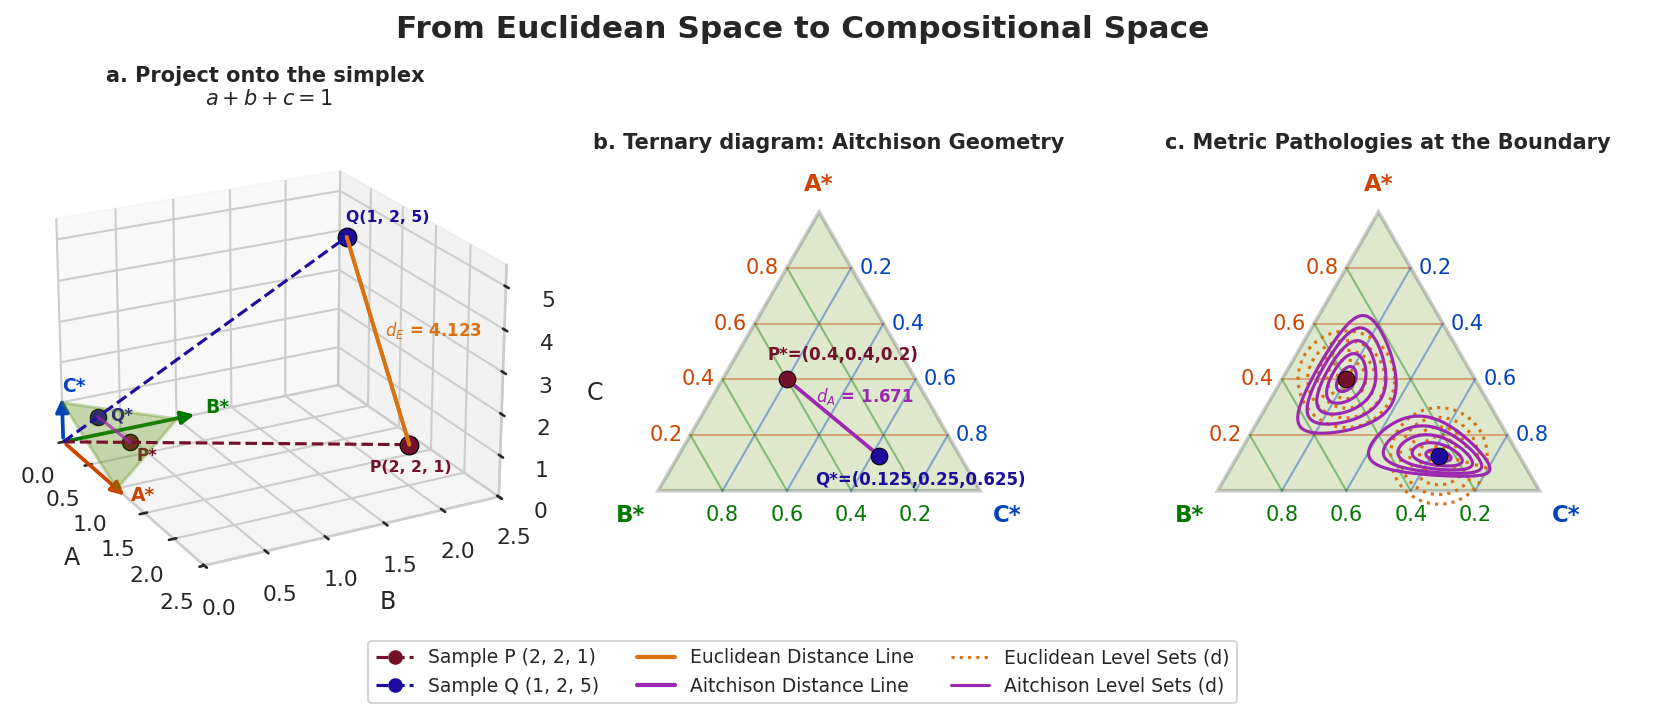

In [140]:
sns.set_theme(style='whitegrid', font_scale=0.95)

# ── 3D Arrow Helper ───────────────────────────────────────────────────────────
class Arrow3D(FancyArrowPatch):
    def __init__(self, xs, ys, zs, *args, **kwargs):
        super().__init__((0, 0), (0, 0), *args, **kwargs)
        self._verts3d = xs, ys, zs

    def do_3d_projection(self, renderer=None):
        xs3d, ys3d, zs3d = self._verts3d
        xs, ys, zs = proj3d.proj_transform(xs3d, ys3d, zs3d, self.axes.M)
        self.set_positions((xs[0], ys[0]), (xs[1], ys[1]))
        return min(zs)
    
# ── helper functions ─────────────────────────────────────────────────────────
def _clr_local(v):
    v = np.asarray(v, float)
    return np.log(v) - np.mean(np.log(v))

def draw_point_box(ax, x, y, z, color, lw=0.7, edge_alpha=0.45, face_alpha=0.07):
    """Draw a transparent bounding box from the origin to point (x, y, z)."""
    edges = [
        [(x,0,0),(x,y,0)], [(0,y,0),(x,y,0)], [(0,0,z),(x,0,z)], [(0,0,z),(0,y,z)],
        [(x,0,z),(x,y,z)], [(0,y,z),(x,y,z)], [(x,0,0),(x,0,z)], [(0,y,0),(0,y,z)], 
        [(x,y,0),(x,y,z)],
    ]
    for (x0,y0,z0),(x1,y1,z1) in edges:
        ax.plot([x0,x1],[y0,y1],[z0,z1], color=color, lw=lw, alpha=edge_alpha, ls=':', zorder=2)

    faces = [
        [(0,0,0),(x,0,0),(x,y,0),(0,y,0)], [(0,0,z),(x,0,z),(x,y,z),(0,y,z)],
        [(0,y,0),(x,y,0),(x,y,z),(0,y,z)], [(0,0,0),(x,0,0),(x,0,z),(0,0,z)],
        [(0,0,0),(0,y,0),(0,y,z),(0,0,z)], [(x,0,0),(x,y,0),(x,y,z),(x,0,z)],
    ]
    poly = Poly3DCollection(faces, alpha=face_alpha, facecolor=color, edgecolor='none', zorder=1)
    ax.add_collection3d(poly)

def get_clr_ring_ternary(center_comp, radius, n_points=100):
    """Generates an Aitchison circle (ring) transformed back to simplex coordinates."""
    t = np.linspace(0, 2*np.pi, n_points)
    v1 = np.array([1, -1, 0]) / np.sqrt(2)
    v2 = np.array([1, 1, -2]) / np.sqrt(6)
    
    center_clr = clr(center_comp)
    ring_points_clr = []
    for angle in t:
        p_clr = center_clr + radius * (np.cos(angle) * v1 + np.sin(angle) * v2)
        ring_points_clr.append(clr_inv(p_clr))
    return np.array(ring_points_clr)

# ── data for panels a, b, c ──────────────────────────────────────────────────
a, b, c = 2, 2, 1     # P
q, r, s = 1, 2, 5     # Q
a_close, b_close, c_close = a/(a+b+c), b/(a+b+c), c/(a+b+c)
q_close, r_close, s_close = q/(q+r+s), r/(q+r+s), s/(q+r+s)

d_E = float(np.linalg.norm([a - q, b - r, c - s]))
d_A = float(np.linalg.norm(_clr_local([a, b, c]) - _clr_local([q, r, s])))

# ── figure layout ─────────────────────────────────────────────────────────────
fig = plt.figure(figsize=(14, 5), dpi=150, facecolor='white')
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.1, hspace=0.0)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL A — Normalise onto the simplex
# ═════════════════════════════════════════════════════════════════════════════
ax1 = fig.add_subplot(gs[0, 0], projection='3d')

V = np.array([[1,0,0],[0,1,0],[0,0,1]], float)
ax1.add_collection3d(Poly3DCollection([V.tolist()], alpha=0.30,
                                       facecolor=OLIVE, edgecolor=OLIVE, linewidths=1.5))

# ── colored axis arrows representing A%, B%, C% ──
AX_MAX2 = 1.2
AX2_MAX1 = 5
AX2_MAX2 = 2
for xs, ys, zs, col, lbl, tp in [
    ([0, AX_MAX2], [0, 0],       [0, 0],       A_COLOR, 'A*', (AX_MAX2+0.06, 0, 0)),
    ([0, 0],       [0, AX_MAX2], [0, 0],       B_COLOR, 'B*', (0, AX_MAX2+0.06, 0)),
    ([0, 0],       [0, 0],       [0, AX_MAX2], C_COLOR, 'C*', (0, 0, AX_MAX2+0.06)),
]:
    arr = Arrow3D(xs, ys, zs, arrowstyle="-|>", mutation_scale=13, lw=1.8, color=col, zorder=3)
    ax1.add_artist(arr)
    ax1.text(*tp, lbl, fontsize=9, fontweight='bold', color=col)

# ── lines from origin to P and Q ──
ax1.plot([0, a],[0, b],[0, c], color=CRIMSON, lw=1.5, ls='--', zorder=5)
ax1.plot([0, q],[0, r],[0, s], color=INDIGO, lw=1.5, ls='--', zorder=5)

# ── original points ──
ax1.scatter([a],[b],[c], color=CRIMSON, s=80, zorder=10, edgecolors='black', linewidths=0.6)
ax1.text(a + 0.1, b - 0.4, c - 0.3, f'P({a}, {b}, {c})',
         fontsize=7.5, fontweight='bold', color=CRIMSON)

ax1.scatter([q],[r],[s], color=INDIGO, s=80, zorder=10, edgecolors='black', linewidths=0.6)
ax1.text(q + 0.02, r - 0.02, s + 0.4, f'Q({q}, {r}, {s})',
         fontsize=7.5, fontweight='bold', color=INDIGO)

# ── Euclidean distance line ──
ax1.plot([a, q],[b, r],[c, s], color=DIST_E, lw=1.8, zorder=6)
mx, my, mz = (a+q)/2, (b+r)/2, (c+s)/2

# ── distance line between normalized P and Q ──
ax1.plot([a_close,q_close],[b_close,r_close],[c_close,s_close], color=DIST_A, lw=1.6, zorder=6, alpha=0.7)

# ── percentage points ──
ax1.scatter([a_close],[b_close],[c_close], color=CRIMSON, s=60, zorder=11, edgecolors='black', linewidths=0.7)
ax1.text(a_close + 0.06, b_close + 0.02, c_close - 0.4,
         'P*',
         fontsize=8, fontweight='bold', color=CRIMSON)

ax1.plot([a, q],[b, r],[c, s], color=DIST_E, lw=1.8, zorder=6)
mx, my, mz = (a+q)/2, (b+r)/2, (c+s)/2
ax1.text(mx - 0.04, my + 0.09, mz + 0.02,
         f'$d_E$ = {d_E:.3f}', fontsize=8, color=DIST_E, fontweight='bold')

ax1.scatter([q_close],[r_close],[s_close], color=INDIGO, s=60, zorder=11, edgecolors='black', linewidths=0.7)
ax1.text(q_close + 0.05, r_close + 0.08, s_close - 0.08,
         'Q*',
         fontsize=8, fontweight='bold', color=INDIGO)
ax1.set_xlim(0, AX2_MAX2+0.5); ax1.set_ylim(0, AX2_MAX2+0.5); ax1.set_zlim(0, AX2_MAX1+0.5)
ax1.set_xlabel('A'); ax1.set_ylabel('B'); ax1.set_zlabel('C')
ax1.set_title('a. Project onto the simplex \n$a + b + c = 1$', #
              fontsize=10, fontweight='bold', pad=2)
ax1.view_init(elev=22, azim=-28)

# ═════════════════════════════════════════════════════════════════════════════
# COMMON TERNARY LOGIC FOR PANELS B & C
# ═════════════════════════════════════════════════════════════════════════════
TA = np.array([0.5, np.sqrt(3)/2])
TB = np.array([0.0, 0.0])
TC = np.array([1.0, 0.0])

def t2d(p_, q_, r_):
    return p_*TA + q_*TB + r_*TC

def draw_ternary_base(ax, title):
    ax.set_aspect('equal'); ax.set_axis_off()
    tri_patch = plt.Polygon([TA, TB, TC], facecolor=OLIVE, edgecolor='black', lw=1.8, alpha=0.2, zorder=1)
    ax.add_patch(tri_patch)

    for v in [0.2, 0.4, 0.6, 0.8]:
        # Grid lines for A (constant A)
        p1, p2 = t2d(v, 1-v, 0), t2d(v, 0, 1-v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=A_COLOR, lw=1, alpha=0.4, zorder=2)
        
        # Grid lines for B (constant B)
        p1, p2 = t2d(1-v, v, 0), t2d(0, v, 1-v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=B_COLOR, lw=1, alpha=0.4, zorder=2)
        
        # Grid lines for C (constant C)
        p1, p2 = t2d(1-v, 0, v), t2d(0, 1-v, v)
        ax.plot([p1[0],p2[0]], [p1[1],p2[1]], color=C_COLOR, lw=1, alpha=0.4, zorder=2)

        # --- GRID LABELS ---
        # Left edge (A labels)
        pt_A = t2d(v, 1-v, 0)
        ax.text(pt_A[0]-0.025, pt_A[1], f'{v}', fontsize=10, color=A_COLOR, ha='right', va='center')
        
        # Bottom edge (B labels)
        pt_B = t2d(0, v, 1-v)
        ax.text(pt_B[0], pt_B[1]-0.045, f'{v}', fontsize=10, color=B_COLOR, ha='center', va='top')
        
        # Right edge (C labels)
        pt_C = t2d(v, 0, 1-v)
        c_val = round(1 - v, 1)
        ax.text(pt_C[0]+0.025, pt_C[1], f'{c_val}', fontsize=10, color=C_COLOR, ha='left', va='center')

    # --- CORNER LABELS ---
    # Top corner (A)
    ax.text(TA[0], TA[1] + 0.05, 'A*', fontsize=11, fontweight='bold', color=A_COLOR, ha='center', va='bottom')
    
    # Bottom-left corner (B)
    ax.text(TB[0] - 0.04, TB[1] - 0.04, 'B*', fontsize=11, fontweight='bold', color=B_COLOR, ha='right', va='top')
    
    # Bottom-right corner (C)
    ax.text(TC[0] + 0.04, TC[1] - 0.04, 'C*', fontsize=11, fontweight='bold', color=C_COLOR, ha='left', va='top')

    ax.set_xlim(-0.26, 1.32); ax.set_ylim(-0.26, 1.05)
    ax.set_title(title, fontsize=10, fontweight='bold', pad=2)

# ═════════════════════════════════════════════════════════════════════════════
# PANEL B — Ternary Diagram (Points)
# ═════════════════════════════════════════════════════════════════════════════
ax2 = fig.add_subplot(gs[0, 1])
draw_ternary_base(ax2, 'b. Ternary diagram: Aitchison Geometry')

P2 = t2d(a_close, b_close, c_close)
Q2 = t2d(q_close, r_close, s_close)

ax2.plot(*P2, 'o', color=CRIMSON, markersize=8, markeredgecolor='black', markeredgewidth=0.5, zorder=10)
ax2.text(P2[0]-0.06, P2[1]+0.06, f"P*=({a_close},{b_close},{c_close})", fontsize=8, fontweight='bold', color=CRIMSON)

ax2.plot(*Q2, 'o', color=INDIGO, markersize=8, markeredgecolor='black', markeredgewidth=0.5, zorder=10)
ax2.text(Q2[0]-0.2, Q2[1]-0.09, f"Q*=({q_close},{r_close},{s_close})", fontsize=8, fontweight='bold', color=INDIGO)

ax2.plot([P2[0], Q2[0]], [P2[1], Q2[1]], color=DIST_A, lw=1.8, zorder=5)
tm = (P2 + Q2) / 2
ax2.text(tm[0] + 0.1, tm[1] + 0.05, f'$d_A$ = {d_A:.3f}', fontsize=8, color=DIST_A, ha='center', fontweight='bold')

# ═════════════════════════════════════════════════════════════════════════════
# PANEL C — Ternary Diagram (Pathologies & Contours)
# ═════════════════════════════════════════════════════════════════════════════
ax3 = fig.add_subplot(gs[0, 2])
draw_ternary_base(ax3, 'c. Metric Pathologies at the Boundary')

points_d = [a_close, b_close, c_close], [q_close, r_close, s_close]
radii_eucl = [0.03, 0.06, 0.09, 0.12, 0.15]
radii_clr = [0.15, 0.3, 0.45, 0.6, 0.75]
colors_d = [CRIMSON, INDIGO]

for pi, p in enumerate(points_d):
    cx, cy = t2d(p[0], p[1], p[2])
    
    # 1. Euclidean Contours (Green, Dotted)
    t = np.linspace(0, 2*np.pi, 100)
    for ra in radii_eucl:
        x_circ = cx + ra * np.cos(t)
        y_circ = cy + ra * np.sin(t)
        ax3.plot(x_circ, y_circ, color=DIST_E, lw=1.5, ls=':', zorder=4)
        
    # 2. Aitchison/CLR Contours (Red, Solid)
    for ra in radii_clr:
        ring_ternary = get_clr_ring_ternary(p, ra)
        x_clr, y_clr = [], []
        for tp in ring_ternary:
            tx, ty = t2d(tp[0], tp[1], tp[2])
            x_clr.append(tx)
            y_clr.append(ty)
        x_clr.append(x_clr[0]); y_clr.append(y_clr[0]) # close loop
        ax3.plot(x_clr, y_clr, color=DIST_A, lw=1.5, ls='-', zorder=5)

    # 3. Center Cross Markers
    ax3.plot([cx], [cy], marker='o', markersize=8, color=colors_d[pi],  markeredgecolor='black', markeredgewidth=0.5,  zorder=6)

# ── Global Title and Legend ──────────────────────────────────────────────────
fig.suptitle('From Euclidean Space to Compositional Space', fontsize=15, fontweight='bold', y=0.96)

legend_elements = [
    Line2D([0],[0], color=CRIMSON, marker='o', ls='--', markersize=6, label=f'Sample P ({a}, {b}, {c})'),
    Line2D([0],[0], color=INDIGO,  marker='o', ls='--', markersize=6, label=f'Sample Q ({q}, {r}, {s})'),
    Line2D([0],[0], color=DIST_E,  lw=2, ls='-', label='Euclidean Distance Line'),
    Line2D([0],[0], color=DIST_A,  lw=2, ls='-', label='Aitchison Distance Line'),
    Line2D([0],[0], color=DIST_E, lw=1.5, ls=':', label='Euclidean Level Sets (d)'),
    Line2D([0],[0], color=DIST_A,   lw=1.5, ls='-', label='Aitchison Level Sets (d)')
]

fig.legend(handles=legend_elements, loc='lower center', ncol=3,
           bbox_to_anchor=(0.5, 0.03), fontsize=9, frameon=True, edgecolor='#cccccc')

for ax in [ax1, ax2, ax3]:
    ax.title.set_y(1.5)
# plt.tight_layout(rect=[0, 0.08, 1, 0.95])
plt.savefig(PLOT_DIR / '1_cartesian_to_ternary_combined.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.savefig(PLOT_DIR / '1_cartesian_to_ternary_combined.svg', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()

# Figure ground true

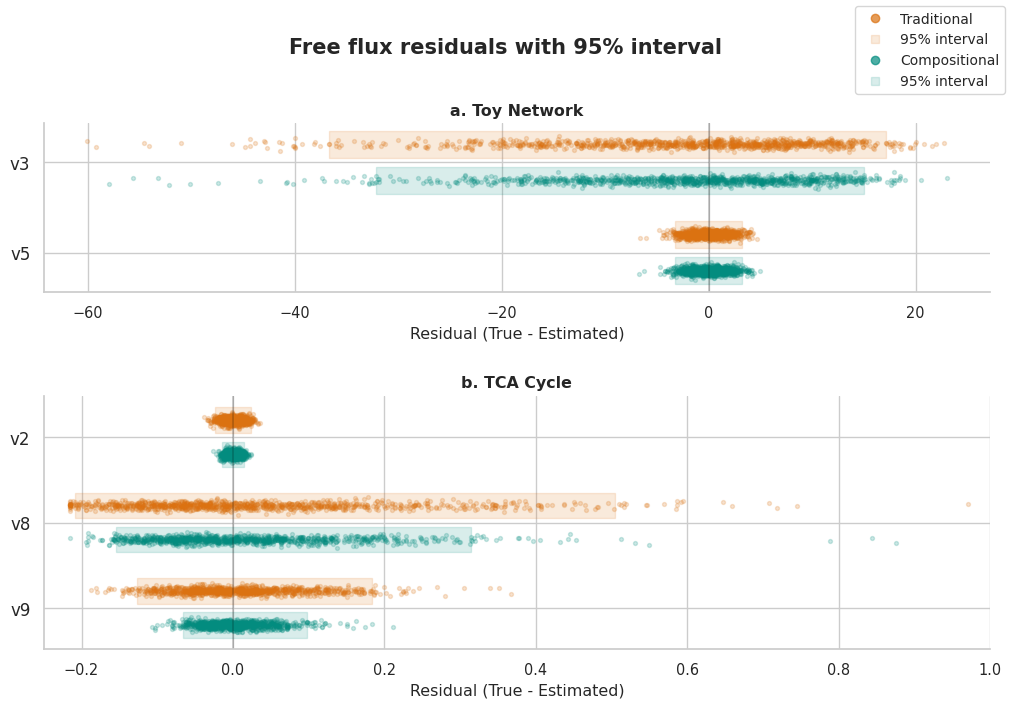

In [141]:
# --- 1. DATA LOADING & RESIDUALS ---
# (Assumes RESULTS_DIR_TOY and RESULTS_DIR_TCA are defined as in previous steps)
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
with open(RESULTS_DIR_TOY / "estimated_fluxes_reference.pkl", "rb") as f:
    est_toy = pickle.load(f)

true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
with open(RESULTS_DIR_TCA / "estimated_fluxes_reference.pkl", "rb") as f:
    est_tca = pickle.load(f)

res_trad_toy = (true_flux_toy[None, [2, 4]] - est_toy["trad"][:, [4, 5]])
res_comp_toy = (true_flux_toy[None, [2, 4]] - est_toy["ilr"][:, [4, 5]])

true_ref_tca = np.array([true_flux_tca[k] for k in ["v8", "v2", "v9"]])
res_trad_tca = est_tca["trad"][:, :] - true_ref_tca[None, :]
res_comp_tca = est_tca["ilr"][:, :] - true_ref_tca[None, :]

# --- 2. PLOTTING ---

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), 
                               gridspec_kw={'height_ratios': [2, 3], 'hspace': 0.1}, layout="constrained")

def draw_scatter_with_95_interval(ax, trad_data, comp_data, labels):
    positions = np.arange(len(labels))[::-1]
    
    for i, pos in enumerate(positions):
        data_pairs = [
            (trad_data[i], pos + 0.2, TRAD, 'Traditional'),
            (comp_data[i], pos - 0.2, ILR, 'Compositional')
        ]
        
        for data, y_pos, color, label in data_pairs:
            # Calculate 95% Interval (2.5% to 97.5%)
            lower = np.percentile(data, 2.5)
            upper = np.percentile(data, 97.5)
            
            # Draw the 95% Sample Space Box
            rect = Rectangle((lower, y_pos - 0.15), upper - lower, 0.3, 
                             linewidth=1, edgecolor=color, facecolor=color, alpha=0.15)
            ax.add_patch(rect)
            
            # Draw Jittered Scatter Points
            jitter = np.random.normal(y_pos, 0.03, size=len(data))
            ax.scatter(data, jitter, color=color, s=8, alpha=0.20, label=label if i==0 else "")
            

    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=12)
    ax.axvline(0, color='black', linestyle='-', alpha=0.2, lw=1.2)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Render Toy Network
draw_scatter_with_95_interval(ax1, 
                              [res_trad_toy[:, 0], res_trad_toy[:, 1]], 
                              [res_comp_toy[:, 0], res_comp_toy[:, 1]], 
                              ["v3", "v5"])
ax1.set_title("a. Toy Network", fontweight='bold')
ax1.set_xlabel("Residual (True - Estimated)")

# Render TCA Cycle
draw_scatter_with_95_interval(ax2, 
                              [res_trad_tca[:, 1], res_trad_tca[:, 0], res_trad_tca[:, 2]], 
                              [res_comp_tca[:, 1], res_comp_tca[:, 0], res_comp_tca[:, 2]], 
                              ["v2", "v8", "v9"])
ax2.set_xlim(-0.25,1)
ax2.set_title("b. TCA Cycle", fontweight='bold')
ax2.set_xlabel("Residual (True - Estimated)")

# Custom legend
custom_marker = [
    Line2D([0], [0], color=TRAD, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=TRAD, marker="s", linestyle="", markersize=6, alpha = 0.15),
    Line2D([0], [0], color=ILR, marker="o", linestyle="", markersize=6, alpha = 0.7),
    Line2D([0], [0], color=ILR, marker="s", linestyle="", markersize=6, alpha = 0.15),
]
fig.legend(custom_marker, ["Traditional", "95% interval", "Compositional", "95% interval"], fontsize=10, loc="outside upper right") #, bbox_to_anchor=(1.1,0.6)
fig.suptitle("Free flux residuals with 95% interval", fontsize=15, fontweight='bold', y=0.95)
plt.savefig(PLOT_DIR / 'flux_residuals.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()

Caption: 
Flux residuals 
For TCA cycle the plot is cuttet at 1, not showing 6 outliers for TCA cycle v8 traditional I-MFA 

# Figure mse diff 

In [142]:
true_flux_toy = np.load(RESULTS_DIR_TOY / "true_flux.npy")
free_fluxes_toy = np.load(RESULTS_DIR_TOY / "free_fluxes.npy")

with open(RESULTS_DIR_TOY / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_toy = pickle.load(f)

resid_trad_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["trad"][:, :, [4, 5]])
resid_ilr_toy = (free_fluxes_toy[:, None, :] - estimated_fluxes_toy["ilr"][:, :, [4, 5]])

mse_trad_toy = (resid_trad_toy ** 2).mean(axis=(0, 1))
mse_ilr_toy = (resid_ilr_toy ** 2).mean(axis=(0, 1))

diff_flux_toy = ((resid_trad_toy ** 2).mean(axis=1) - (resid_ilr_toy ** 2).mean(axis=1))

In [143]:
true_flux_tca = np.load(RESULTS_DIR_TCA / "true_flux.npy", allow_pickle=True).item()
free_fluxes_tca = jnp.load(RESULTS_DIR_TCA / "free_fluxes.npy", allow_pickle=True)

with open(RESULTS_DIR_TCA / "estimated_fluxes.pkl", "rb") as f:
    estimated_fluxes_tca = pickle.load(f)

resid_trad_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["trad"][:, :, :])
resid_ilr_tca = (free_fluxes_tca[:, None, :] - estimated_fluxes_tca["ilr"][:, :, :])

mse_trad_tca = (resid_trad_tca ** 2).mean(axis=(0, 1))
mse_ilr_tca = (resid_ilr_tca ** 2).mean(axis=(0, 1))

diff_flux_tca= ((resid_trad_tca ** 2).mean(axis=1) - (resid_ilr_tca ** 2).mean(axis=1))

free_flux_numbers = jnp.array([8,2,9])

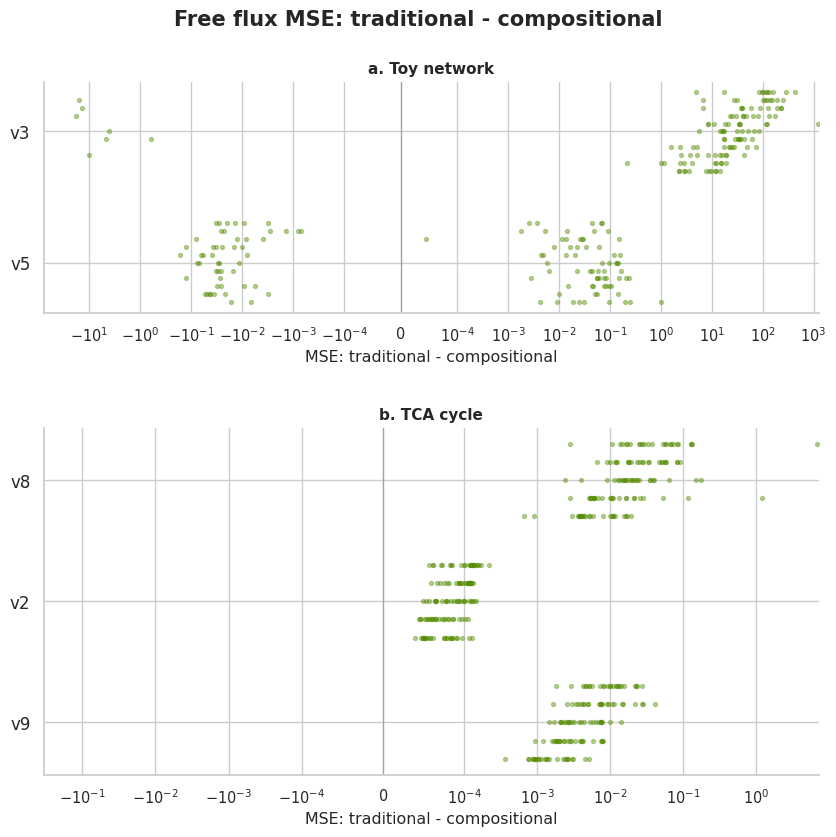

In [144]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 9), 
                               gridspec_kw={'height_ratios': [2, 3], 'hspace': 0.4})

def draw_scatter_ordered(ax, diff_data, flux_val, labels):
    positions = np.arange(len(labels))[::-1]
    
    for i, pos in enumerate(positions):
        xmin = flux_val[i].min()
        xmax = flux_val[i].max()
        a, b = -0.3, 0.3
        flux_scaled = a + (flux_val[i] - xmin) * (b - a) / (xmax - xmin)
        data_pairs = [
            (diff_data[i], pos + flux_scaled)
        ]
        for data, y_pos in data_pairs:            
            ax.scatter(data, y_pos, color=OLIVE, s=8, alpha=0.40)
    ax.set_yticks(positions)
    ax.set_yticklabels(labels, fontsize=12)
    ax.axvline(0, color='black', linestyle='-', alpha=0.2, lw=1)
    
    for spine in ['top', 'right']:
        ax.spines[spine].set_visible(False)

# Render Toy Network
draw_scatter_ordered(ax1, 
                    [diff_flux_toy[:, 0], diff_flux_toy[:, 1]], 
                    [free_fluxes_toy[:, 0], free_fluxes_toy[:, 1]], 
                    ["v3", "v5"])
ax1.set_title("a. Toy network", fontweight='bold', fontsize=11)
ax1.set_xscale("symlog", linthresh=1e-4)
ax1.set_xlabel("MSE: traditional - compositional")


draw_scatter_ordered(ax2, 
                    [diff_flux_tca[:, 0], diff_flux_tca[:, 1], diff_flux_tca[:, 2]], 
                    [free_fluxes_tca[:, 0], free_fluxes_tca[:, 1], free_fluxes_tca[:, 2]], 
                    ["v8","v2", "v9"])
ax2.set_title("b. TCA cycle", fontweight='bold', fontsize=11)
ax2.set_xlabel("MSE: traditional - compositional")
ax2.set_xscale("symlog", linthresh=1e-4)

fig.suptitle("Free flux MSE: traditional - compositional", fontsize=15, fontweight='bold', y=0.96)
plt.savefig(PLOT_DIR /'mse_difference.png', dpi=300, bbox_inches='tight', pad_inches=0.12)
plt.show()